# Диференційована нечітка редукція графів: математичні основи та експериментальне дослідження
## Інтерактивний розрахунковий ноутбук (`labflow`)

**Версії ноутбука**: [Українська версія](walkthrough_experiments_ua.ipynb) | [English Edition](walkthrough_experiments_en.ipynb)

---

### 1. Постановка задачі та парадигма Select-Reduce-Connect (SRC)

Ієрархічні графові нейронні мережі (GNN) використовують **оператори редукції графів (pooling / coarse-graining)** для стиснення вхідного графа $G = (V, E, A, X)$ у компактний суперграф $G_{new} = (V_{new}, E_{new}, A_{new}, X_{new})$ із кількістю супервузлів $K \ll N$.

Класичні білінійні та спектральні методи — **DiffPool**, **MinCutPool** та **DMoN** — спираються на стандартну матричну алгебру $(\mathbb{R}, +, \times)$ над симплексом Softmax і мають чотири структурні обмеження:
1. **Вибух масштабу ваг і вихід за межі $[0, 1]$**:
   Білінійна форма $A_{new} = S^T A S$ зберігає повну суму ваг ребер $\sum A_{new} = \sum A = 2M$. При стисненні матриці з $N \times N$ до $K \times K$ середня вага супер-ребер зростає пропорційно $(N/K)^2$, руйнуючи інтервал $[0, 1]$.
2. **Втрата топологічної розрідженості**:
   Редукована матриця суміжності стає повністю щільною ($0\%$ точних нулів).
3. **Взаємне гасіння різнознакових ознак**:
   Лінійне усереднення $X_{new} = S^T H$ призводить до взаємного знищення додатних і від'ємних активацій вузлів (наприклад, $H_1 = +5.0$, $H_2 = -5.0 \implies X_{new} = 0.0$ для `ELU` / `LeakyReLU`).
4. **Відсутність квантора загальності ($\forall$)**:
   Операції підсумовування та супремуму реалізують лише квантор існування ($\exists$). Для виділення клік і щільних структурних мотивів необхідна перевірка зв'язності між **усіма** парами вузлів кластера ($\forall i, j$).

#### Парадигма Select-Reduce-Connect (SRC)
У пакеті `labflow` кожен шар редукції декомпозується на три диференційовані етапи:
- **Select**: Проекція мікро-вузлів у матрицю належності $S \in [0, 1]^{N \times K}$.
- **Reduce**: Нелінійна агрегація ознак $X_{new} = \text{Pool}_X(H, S)$ (центр ваги COG, біполярний супремум, інтеграл Шоке).
- **Connect**: Редукція топології $A_{new} = \text{Reduce}_A(A, S)$ через неперервні t-норми ($\top$), t-конорми ($\bot$) та нечіткі імплікації ($\to$).


In [1]:
# 1. Налаштування середовища та імпорт пакету labflow
import csv
import json
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]
plt.rcParams["axes.unicode_minus"] = False

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Пристрій: {device} | PyTorch: {torch.__version__}")

from labflow.classical import DiffPoolReducer, DMoNReducer, MinCutPoolReducer
from labflow.composite import (
    CANONICAL_METHOD_SPECS,
    METHOD_SPEC_MAP,
    GraphReductionLayer,
    build_membership,
)
from labflow.fuzzy_features import BipolarSupremalFeaturePooling
from labflow.fuzzy_relational import LukasiewiczTopologyReducer
from labflow.fuzzy_smooth import BandlerKohoutTopologyReducer, ProbSumTopologyReducer
from labflow.gnn import BaseGraphEncoder
from labflow.types import GraphData, dense_to_sparse

print(f"Завантажено пакет labflow ({len(CANONICAL_METHOD_SPECS)} канонічних конфігурацій редукції).")


Пристрій: cuda | PyTorch: 2.15.0+cu132
Завантажено пакет labflow (22 канонічних конфігурацій редукції).


---
### 2. Двогілковий GNN-енкодер та оператори належності

Для вхідного графа $G = (A, X)$, де $A \in [0, 1]^{N \times N}$ та $X \in \mathbb{R}^{N \times F}$:
- **Мікро-вузли**: індекси $i, j \in \{1, \dots, N\}$
- **Макро-вузли (супервузли)**: індекси $I, J \in \{1, \dots, K\}$, $K \ll N$

Енкодер обчислює матрицю вузлових ембедингів $H$ та логіти кластеризації $Z$ за час $\mathcal{O}(MF + NFF')$:
1. **Симетрично нормована суміжність із петлями**:
   $$\hat{A} = \tilde{D}^{-1/2} (A + I_N) \tilde{D}^{-1/2}, \quad \tilde{D}_{ii} = 1 + \sum_{j=1}^N A_{ij}$$
2. **Гілка ембедингів ознак**:
   $$H = \text{ELU}\left( \hat{A} X W_{msg, e} + X W_{self, e} + \mathbf{b}_e^T \right) \in \mathbb{R}^{N \times F'}$$
3. **Гілка кластерного призначення**:
   $$Z = \hat{A} X W_{msg, p} + X W_{self, p} + \mathbf{b}_p^T \in \mathbb{R}^{N \times K}$$
4. **Оператори належності**:
   - **Симплекс Softmax**: $S_{iI} = \frac{\exp(Z_{iI} / \tau)}{\sum_{J=1}^K \exp(Z_{iJ} / \tau)}$, де $\sum_{I=1}^K S_{iI} = 1$.
   - **Анізотропний сигмоїд**: $S_{iI} = \sigma(\gamma_I Z_{iI} + \beta_I) \in [0, 1]$, що дозволяє вузлам належати кільком спільнотам одночасно.


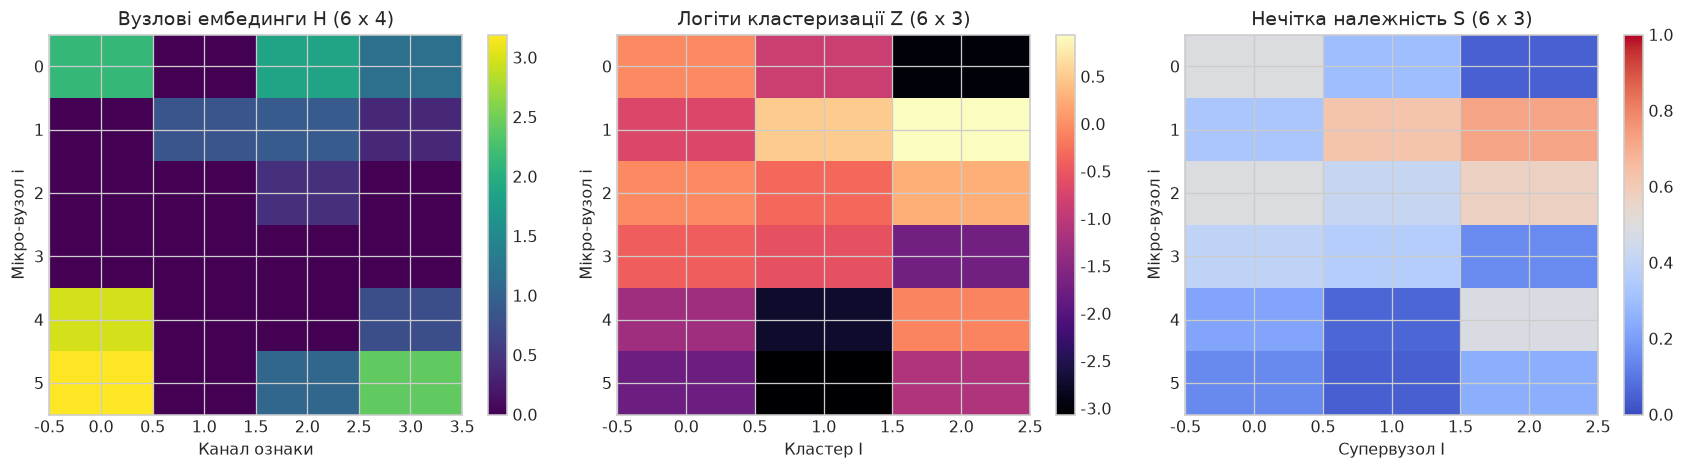

In [2]:
# 2. Демонстрація роботи двогілкового енкодера та функцій належності (N=6, F=7, K=3)
torch.manual_seed(42)
N, F_in, F_out, K = 6, 7, 4, 3

adj_demo = torch.zeros((N, N), dtype=torch.float32)
for i in range(N):
    adj_demo[i, (i + 1) % N] = 1.0
    adj_demo[(i + 1) % N, i] = 1.0
x_demo = torch.randn((N, F_in), dtype=torch.float32)

encoder = BaseGraphEncoder(in_features=F_in, embed_dim=F_out, pool_dim=K, embed_activation="relu")
h, z = encoder(adj_demo, x_demo)

membership_fn = build_membership("sigmoid", num_clusters=K)
s_fuzzy = membership_fn(z)
membership_softmax = build_membership("softmax", num_clusters=K)
s_softmax = membership_softmax(z)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
im0 = axes[0].imshow(h.detach().numpy(), cmap="viridis", aspect="auto")
axes[0].set_title(f"Вузлові ембединги H ({N} x {F_out})")
axes[0].set_xlabel("Канал ознаки")
axes[0].set_ylabel("Мікро-вузол i")
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(z.detach().numpy(), cmap="magma", aspect="auto")
axes[1].set_title(f"Логіти кластеризації Z ({N} x {K})")
axes[1].set_xlabel("Кластер I")
axes[1].set_ylabel("Мікро-вузол i")
plt.colorbar(im1, ax=axes[1])

im2 = axes[2].imshow(s_fuzzy.detach().numpy(), cmap="coolwarm", vmin=0, vmax=1, aspect="auto")
axes[2].set_title(f"Нечітка належність S ({N} x {K})")
axes[2].set_xlabel("Супервузол I")
axes[2].set_ylabel("Мікро-вузол i")
plt.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()


---
### 3. Класичні спектральні та білінійні методи (`DiffPool`, `MinCutPool`, `DMoN`)

1. **DiffPool (`M1`)**: $A_{new} = S^T A S$, $X_{new} = S^T H$. Зберігає реберну масу $\sum A_{new} = 2M$, через що при великих $N/K$ ваги супер-ребер виходять далеко за межі $[0, 1]$.
2. **MinCutPool (`M2`)**: Мінімізує спектральний розріз $\mathcal{L}_{cut} = -\frac{\text{Tr}(S^T \tilde{A} S)}{\text{Tr}(S^T \tilde{D} S)}$ та примусово зануляє діагональ $A_{new}(I, I) = 0$, втрачаючи інформацію про внутрішню кліковість кластерів.
3. **DMoN (`M3`)**: Оптимізує модулярність Ньюмана-Гірвана відносно нуль-моделі Чунга-Лу $B = A - \frac{\mathbf{d}\mathbf{d}^T}{2M}$ та нормує ознаки на об'єм кластера $D_S^{-1} S^T H$.


Метод              | max(A_new)  | min(A_new)  | Нулі (%)  | В межах [0, 1] 
---------------------------------------------------------------------------
DiffPool (M1)      | 1.97        | 0.682       | 0.0%      | НІ (> 1.0)     
MinCutPool (M2)    | 0.643       | 0.0         | 33.3%     | ТАК            
DMoN (M3)          | 0.643       | 0.0         | 33.3%     | ТАК            


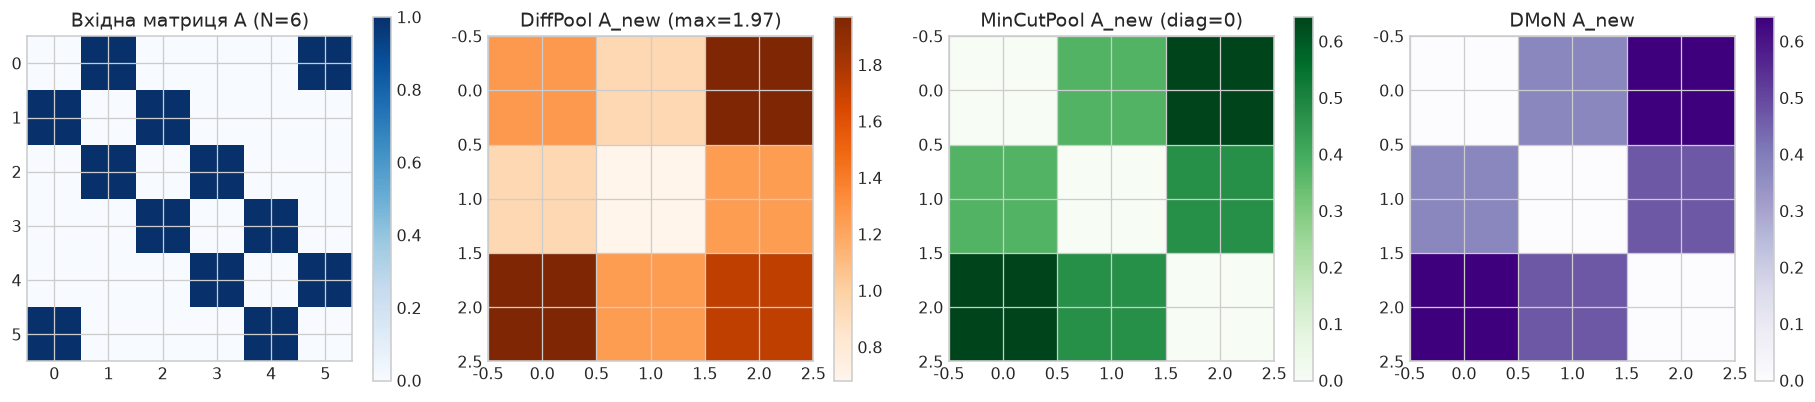

In [3]:
# 3. Порівняння класичних редукторів та діагностика інваріантів
diffpool_red = DiffPoolReducer()
mincut_red = MinCutPoolReducer()
dmon_red = DMoNReducer()

out_diff = diffpool_red(adj_demo, h, s_softmax)
out_mincut = mincut_red(adj_demo, h, s_softmax)
out_dmon = dmon_red(adj_demo, h, s_softmax)

def get_diagnostics(name, adj_tensor):
    a_max = float(adj_tensor.max().item())
    a_min = float(adj_tensor.min().item())
    zeros = float((adj_tensor == 0.0).float().mean().item()) * 100.0
    in_unit = bool(a_min >= -1e-5 and a_max <= 1.0 + 1e-5)
    return {
        "Метод": name,
        "max(A_new)": round(a_max, 3),
        "min(A_new)": round(a_min, 3),
        "Нулі (%)": f"{zeros:.1f}%",
        "В межах [0, 1]": "ТАК" if in_unit else "НІ (> 1.0)",
    }

diags = [
    get_diagnostics("DiffPool (M1)", out_diff.adj_new),
    get_diagnostics("MinCutPool (M2)", out_mincut.adj_new),
    get_diagnostics("DMoN (M3)", out_dmon.adj_new),
]

print(f"{'Метод':<18} | {'max(A_new)':<11} | {'min(A_new)':<11} | {'Нулі (%)':<9} | {'В межах [0, 1]':<15}")
print("-" * 75)
for d in diags:
    print(f"{d['Метод']:<18} | {d['max(A_new)']:<11} | {d['min(A_new)']:<11} | {d['Нулі (%)']:<9} | {d['В межах [0, 1]']:<15}")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
im_orig = axes[0].imshow(adj_demo.numpy(), cmap="Blues", vmin=0, vmax=1)
axes[0].set_title("Вхідна матриця A (N=6)")
plt.colorbar(im_orig, ax=axes[0])

im_d = axes[1].imshow(out_diff.adj_new.detach().numpy(), cmap="Oranges")
axes[1].set_title(f"DiffPool A_new (max={out_diff.adj_new.max():.2f})")
plt.colorbar(im_d, ax=axes[1])

im_m = axes[2].imshow(out_mincut.adj_new.detach().numpy(), cmap="Greens")
axes[2].set_title("MinCutPool A_new (diag=0)")
plt.colorbar(im_m, ax=axes[2])

im_dm = axes[3].imshow(out_dmon.adj_new.detach().numpy(), cmap="Purples")
axes[3].set_title("DMoN A_new")
plt.colorbar(im_dm, ax=axes[3])

plt.tight_layout()
plt.show()


---
### 4. Імплікативний кванторний пулінг Бандлера-Кохоута (`M11B`)

Реляційні $\sup\text{-}\top$ композиції фіксують зв'язок між кластерами за наявності хоча б одного ребра ($\exists (i, j) \in E$). Для виділення **клік і повнозв'язних структурних мотивів** використовується універсальний квантор ($\forall i, j$):
$$A_{new}^{BK}(I, J) = \min_{i, j \in \{1..N\}} \left( \top(S_{iI}, S_{jJ}) \Rightarrow A_{ij} \right).$$
За імплікацією Кліні-Дінеса $a \Rightarrow_{KD} b = \max(1 - a, b)$:
$$A_{new}^{BK}(I, I) = 1.0 \iff \text{supp}(S_{:, I}) \text{ утворює повну кліку в } G.$$

Завдяки розробленій **Matrix-Free MEX (Minimum Excluded Rank)** декомпозиції на відсортованих стовпцях матриці $S$, оператор обчислюється за $\mathcal{O}((M+N)K \log((M+N)K) + NK^2)$ без побудови щільного доповнення графа $\bar{A}$.


[M11B  ] bk_kleene_dienes   -> Щільність=0.500, F1=0.600, Refl=0.841
[M1    ] diffpool           -> Щільність=0.300, F1=0.467, Refl=20.001
[M2    ] mincut             -> Щільність=0.467, F1=0.400, Refl=0.000


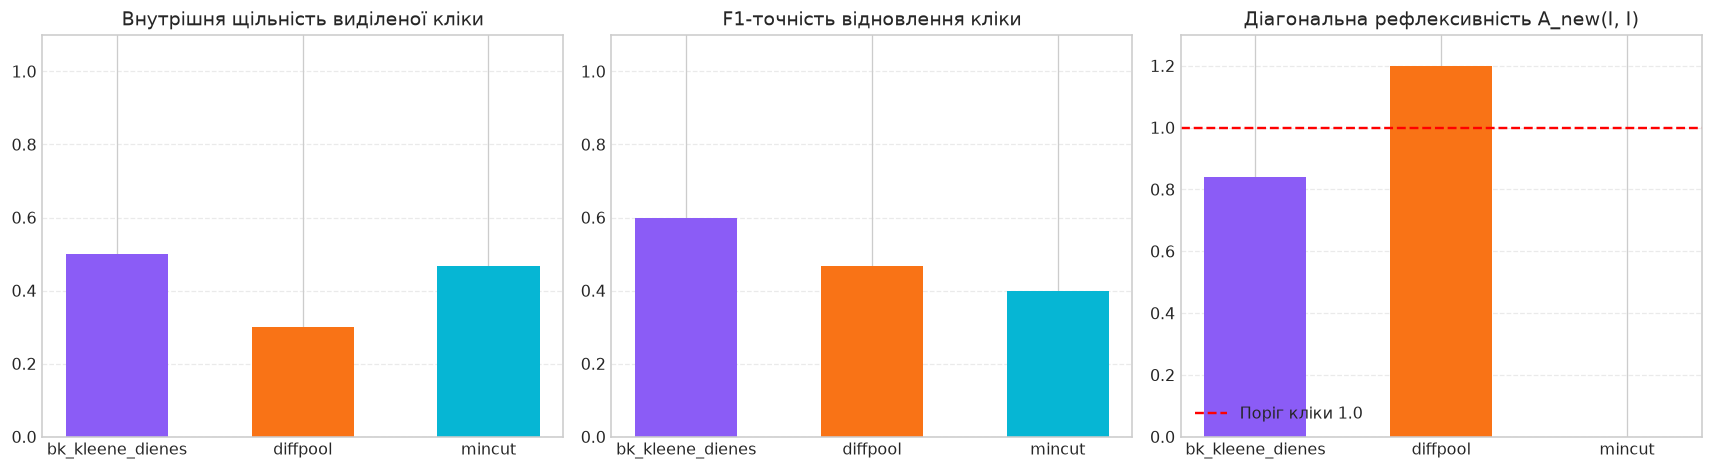

In [4]:
# 4. Бенчмарк виділення вбудованих клік (M11B Bandler-Kohout vs M1 DiffPool vs M2 MinCutPool)
from labflow.benchmarks.clique_motif import run_clique_motif_benchmark

clique_results = run_clique_motif_benchmark(
    method_keys=["bk_kleene_dienes", "diffpool", "mincut"],
    epochs=40,
    seed=42,
    clique_size=5,
    num_cliques=3,
    num_noise_nodes=12,
)

methods = [r.key for r in clique_results]
densities = [r.internal_clique_density for r in clique_results]
f1_scores = [r.clique_recovery_f1 for r in clique_results]
reflexivities = [r.diagonal_reflexivity for r in clique_results]

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
x_pos = np.arange(len(methods))
colors = ["#8b5cf6", "#f97316", "#06b6d4"]

ax[0].bar(x_pos, densities, color=colors, width=0.55)
ax[0].set_title("Внутрішня щільність виділеної кліки")
ax[0].set_xticks(x_pos)
ax[0].set_xticklabels(methods)
ax[0].set_ylim(0, 1.1)
ax[0].grid(axis="y", linestyle="--", alpha=0.4)

ax[1].bar(x_pos, f1_scores, color=colors, width=0.55)
ax[1].set_title("F1-точність відновлення кліки")
ax[1].set_xticks(x_pos)
ax[1].set_xticklabels(methods)
ax[1].set_ylim(0, 1.1)
ax[1].grid(axis="y", linestyle="--", alpha=0.4)

ax[2].bar(x_pos, [min(r, 1.2) for r in reflexivities], color=colors, width=0.55)
ax[2].set_title("Діагональна рефлексивність A_new(I, I)")
ax[2].set_xticks(x_pos)
ax[2].set_xticklabels(methods)
ax[2].set_ylim(0, 1.3)
ax[2].axhline(1.0, color="red", linestyle="--", label="Поріг кліки 1.0")
ax[2].legend(loc="lower left")
ax[2].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

for r in clique_results:
    print(f"[{r.code:<6}] {r.key:<18} -> Щільність={r.internal_clique_density:.3f}, F1={r.clique_recovery_f1:.3f}, Refl={r.diagonal_reflexivity:.3f}")


---
### 5. Нечітка редукція простору ознак: Біполярний супремальний пулінг (`M13A`)

При використанні знакозмінних функцій активації (`ELU`, `LeakyReLU`) лінійне усереднення $X_{new} = D_S^{-1} S^T H$ взаємно гасить додатні та від'ємні пікові активації всередині одного кластера.

**Біполярний супремальний пулінг (`M13A`)** розкладає матрицю $H = H^+ - H^-$ на додатний та від'ємний конуси $H_{if}^\pm = \max(0, \pm H_{if})$ і агрегує кожен конус за супремумом Гогена:
$$X_{new}^+(I, f) = \max_{i=1}^N (S_{iI} H_{if}^+), \quad X_{new}^-(I, f) = \max_{i=1}^N (S_{iI} H_{if}^-), \quad X_{new}^{Bipolar} = X_{new}^+ - X_{new}^-.$$


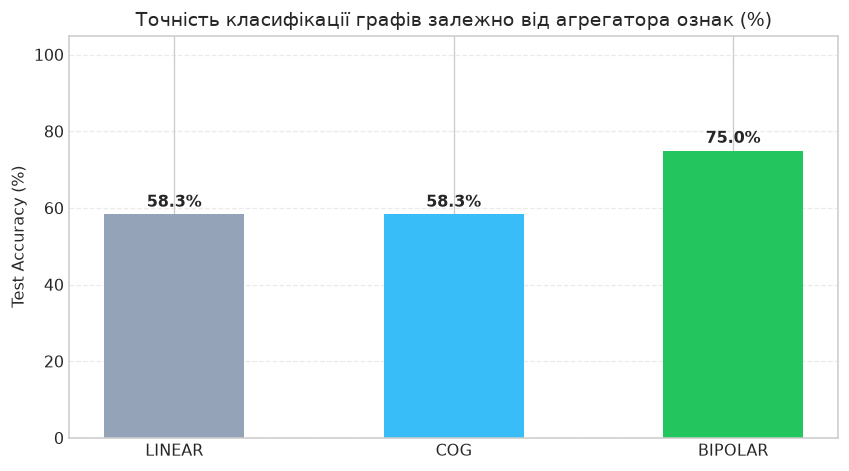

In [5]:
# 5. Абляція операторів пулінгу ознак на задачі ієрархічної класифікації
from labflow.benchmarks.ablation import run_feature_pooling_ablation

feat_ablation = run_feature_pooling_ablation(
    feature_kinds=["linear", "cog", "bipolar"],
    epochs=12,
    seed=123,
)

kinds = [r.variant_name.upper() for r in feat_ablation]
accs = [r.metric_value * 100.0 for r in feat_ablation]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
bars = ax.bar(kinds, accs, color=["#94a3b8", "#38bdf8", "#22c55e"], width=0.5)
ax.set_title("Точність класифікації графів залежно від агрегатора ознак (%)")
ax.set_ylabel("Test Accuracy (%)")
ax.set_ylim(0, 105)
ax.grid(axis="y", linestyle="--", alpha=0.4)

for bar, acc in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width() / 2, acc + 2, f"{acc:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


---
### 6. Масштабно-нормована ймовірнісна сума (`M10-Nm ProbSum-Norm`)

Накопичення $M$ паралельних містків через класичну ймовірнісну конорму $\bot_P(a, b) = 1 - (1-a)(1-b)$ насичується до $1.0$ при зростанні $M$:
$$A_{new}(I, J) = 1 - \prod_{e \in E} (1 - S_{iI} A_{ij} S_{jJ}) \xrightarrow{M \to \infty} 1.0.$$

**Нормований оператор `ProbSum-Norm` (`M10-Nm`)** масштабує логарифмічну суму на коефіцієнт середнього поля $K^2 / M$:
$$A_{new}^{MF}(I, J) = 1 - \exp\left( \frac{K^2}{M} \sum_{e=(i,j) \in E} \ln(1 - S_{iI} A_{ij} S_{jJ} + \epsilon) \right).$$


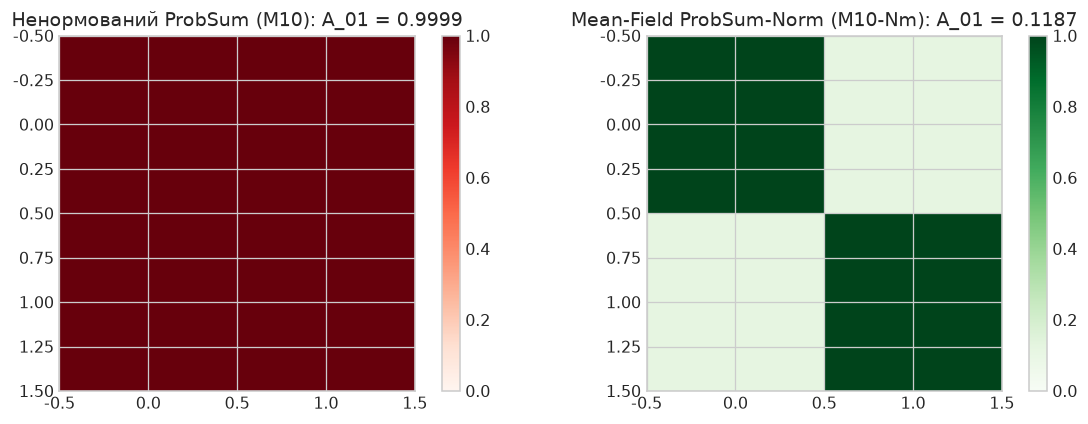

In [6]:
# 6. Експеримент із паралельними містками: ненормований ProbSum vs Mean-Field ProbSum-Norm
from labflow.datasets.synthetic import generate_parallel_bridges_graph

g_bridges, s_bridges = generate_parallel_bridges_graph(cluster_size=8, num_bridges=15, bridge_weight=0.45)
edge_index, edge_weight = g_bridges.sparse_edges()

red_unscaled = ProbSumTopologyReducer(normalization="none")
red_meanfield = ProbSumTopologyReducer(normalization="mean_field")

a_unscaled = red_unscaled(s_bridges, edge_index=edge_index, edge_weight=edge_weight)
a_meanfield = red_meanfield(s_bridges, edge_index=edge_index, edge_weight=edge_weight)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
im0 = axes[0].imshow(a_unscaled.detach().numpy(), cmap="Reds", vmin=0, vmax=1)
axes[0].set_title(f"Ненормований ProbSum (M10): A_01 = {a_unscaled[0, 1].item():.4f}")
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(a_meanfield.detach().numpy(), cmap="Greens", vmin=0, vmax=1)
axes[1].set_title(f"Mean-Field ProbSum-Norm (M10-Nm): A_01 = {a_meanfield[0, 1].item():.4f}")
plt.colorbar(im1, ax=axes[1])

plt.tight_layout()
plt.show()


---
### 7. Згладжений пороговий оператор Лукасевича (`M6-Sm`) та градієнтна динаміка

Жорстка t-норма Лукасевича $\top_L(a, b, c) = \text{clip}(a + b + c - \eta_{IJ}, 0, 1)$ відсікає слабкі зв'язки в нуль, але зануляє похідні ($\nabla_S A_{new} = \mathbf{0}$) для всіх підпорогових супер-ребер на старті навчання.

**Згладжений оператор Лукасевича (`M6-Sm`)** використовує двостороннє вікно Softplus:
$$\phi_\tau(u) = \tau \ln\left(1 + e^{u/\tau}\right) - \tau \ln\left(1 + e^{(u - 1)/\tau}\right) \in (0, 1),$$
яке зберігає ненульовий градієнт на всій області визначення та забезпечує навчання порогового параметра $\eta_{IJ}$.


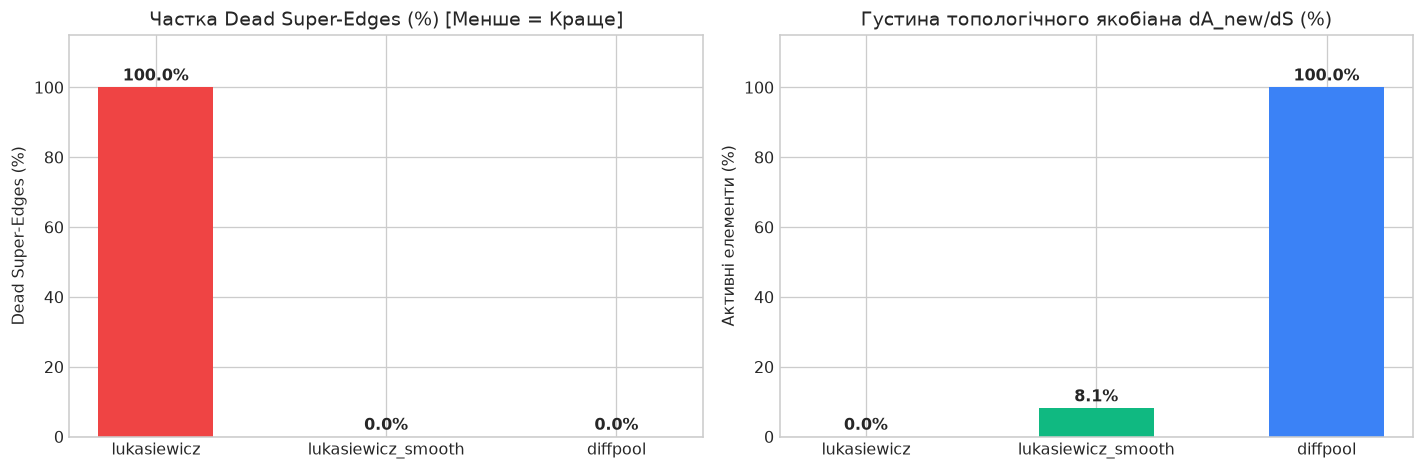

In [7]:
# 7. Порівняння частки мертвих супер-ребер і густини якобіана (M6 vs M6-Sm vs M1)
from labflow.benchmarks.gradient_stability import run_gradient_stability_benchmark

grad_records = run_gradient_stability_benchmark(
    method_keys=["lukasiewicz", "lukasiewicz_smooth", "diffpool"],
    seed=42,
)

methods_g = [r.key for r in grad_records]
dead_ratios = [r.dead_superedge_ratio * 100.0 for r in grad_records]
jac_densities = [r.topo_jacobian_density * 100.0 for r in grad_records]

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2))
bars0 = ax[0].bar(methods_g, dead_ratios, color=["#ef4444", "#10b981", "#3b82f6"], width=0.5)
ax[0].set_title("Частка Dead Super-Edges (%) [Менше = Краще]")
ax[0].set_ylabel("Dead Super-Edges (%)")
ax[0].set_ylim(0, 115)
for b, val in zip(bars0, dead_ratios):
    ax[0].text(b.get_x() + b.get_width() / 2, val + 2, f"{val:.1f}%", ha="center", fontweight="bold")

bars1 = ax[1].bar(methods_g, jac_densities, color=["#ef4444", "#10b981", "#3b82f6"], width=0.5)
ax[1].set_title("Густина топологічного якобіана dA_new/dS (%)")
ax[1].set_ylabel("Активні елементи (%)")
ax[1].set_ylim(0, 115)
for b, val in zip(bars1, jac_densities):
    ax[1].text(b.get_x() + b.get_width() / 2, val + 2, f"{val:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


---
### 8. Парето-фронт на синтетичних бенчмарках (22 методи)

Побудуємо двовимірний Парето-фронт у координатах «Час виконання на великому графі ($N=1200$, мс) — Інтегральний індекс якості».


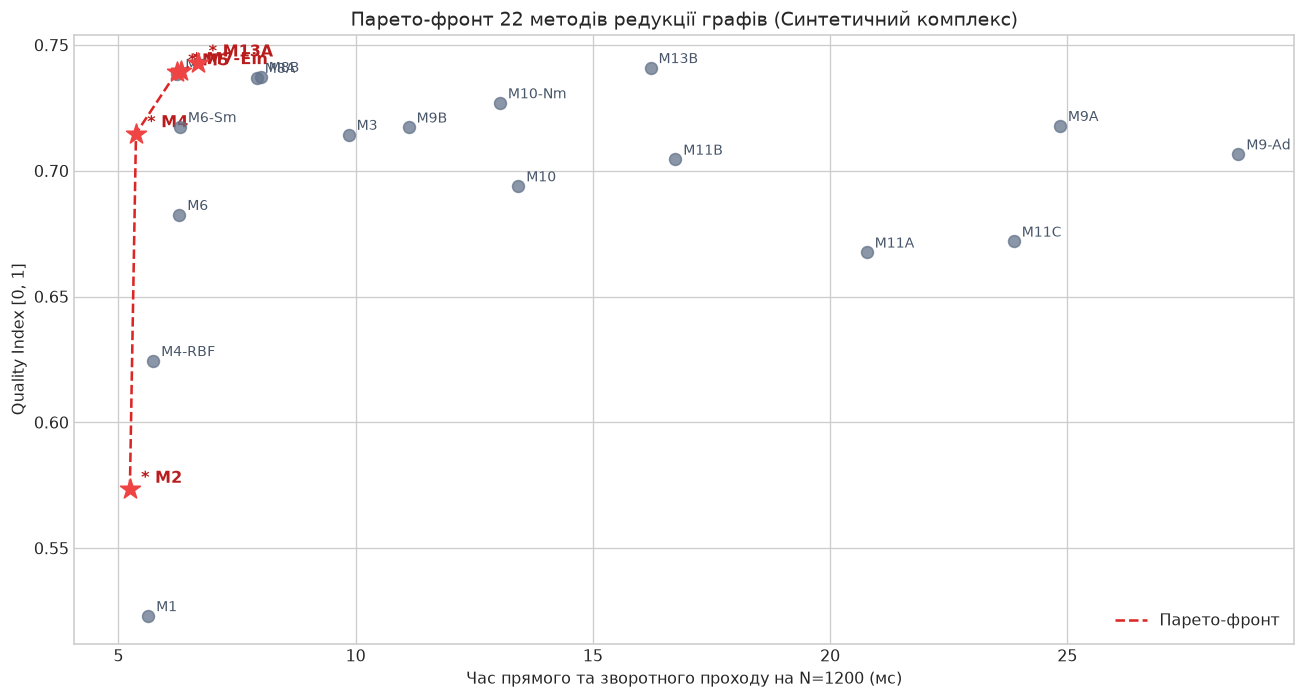

In [8]:
# 8. Побудова Парето-фронту (Час виконання vs Якість)
leaderboard_path = Path("reports/reducer_leaderboard.csv")
if not leaderboard_path.exists():
    leaderboard_path = Path("../reports/reducer_leaderboard.csv")

with open(leaderboard_path, mode="r", encoding="utf-8") as f:
    entries = list(csv.DictReader(f))

codes = [e["method_code"] for e in entries]
times = [float(e["ms_large_graph"]) for e in entries]
qualities = [float(e["quality_index"]) for e in entries]
pareto_flags = [str(e["is_pareto_optimal"]).lower() in ("true", "1") for e in entries]

fig, ax = plt.subplots(figsize=(11.5, 6.2))
for code_lbl, t, q, is_p in zip(codes, times, qualities, pareto_flags):
    if is_p:
        ax.scatter(t, q, color="#ef4444", s=170, marker="*", zorder=5)
        ax.annotate(f"* {code_lbl}", (t, q), textcoords="offset points", xytext=(7, 4), fontweight="bold", color="#b91c1c")
    else:
        ax.scatter(t, q, color="#64748b", s=55, alpha=0.75, zorder=3)
        ax.annotate(code_lbl, (t, q), textcoords="offset points", xytext=(5, 3), color="#475569", fontsize=8.5)

pareto_pts = sorted([(t, q) for t, q, is_p in zip(times, qualities, pareto_flags) if is_p], key=lambda pt: pt[0])
if pareto_pts:
    p_x, p_y = zip(*pareto_pts)
    ax.plot(p_x, p_y, color="#dc2626", linestyle="--", linewidth=1.6, label="Парето-фронт")

ax.set_title("Парето-фронт 22 методів редукції графів (Синтетичний комплекс)")
ax.set_xlabel("Час прямого та зворотного проходу на N=1200 (мс)")
ax.set_ylabel("Quality Index [0, 1]")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


---
### 9. Наочна демонстрація роботи моделей редукції на реальних графах

Продемонструємо роботу ключових моделей безпосередньо на **реальних графах** із трьох контрастних прикладних доменів:
1. **Соціальні его-мережі (`IMDB-BINARY` / `REDDIT-BINARY`)**: Вузли-хаби (актори, які знімаються у фільмах різних жанрів, або модератори гілок обговорень) належать декільком спільнотам одночасно. Порівняємо розподіл сумарної належності вузла $\sum_{I=1}^K S_{iI}$ для нечіткого сигмоїдального призначення (`M6-Sm`) та жорсткого симплексу Softmax (`M1` / `M2`, де $\sum_{I=1}^K S_{iI} \equiv 1$).
2. **Молекулярний скринінг (`NCI109`)**: Порівняємо редуковані матриці суміжності суперграфа $A_{new} \in \mathbb{R}^{K \times K}$, побудовані на реальній молекулі методами `M1 (diffpool)` (вихід за межі $[0, 1]$), `M6-Sm (lukasiewicz_smooth)` (нормована порогова топологія в $[0, 1]$) та `M11B (bk_kleene_dienes)` (імплікативне виділення циклічних підструктур).
3. **Великі білкові структури (`DD`, $\bar{N}=240.7, F=82$)**: Покажемо, як біполярний супремальний пулінг `M13A (goguen_bipolar)` зберігає амплітуду як додатних, так і від'ємних ознак амінокислотних доменів $X_{new}$ порівняно зі звичайним усередненням центру ваги `M5 (goguen)` — що дозволило `M13A` здобути перемогу на `DD` із точністю **70.0%** та **ROC-AUC = 0.833**.


Граф акторів IMDB-BINARY: N=16, M=76, F=18
Молекула NCI109:          N=30, M=68, F=56
Білкова структура DD:     N=208, M=1066, F=82


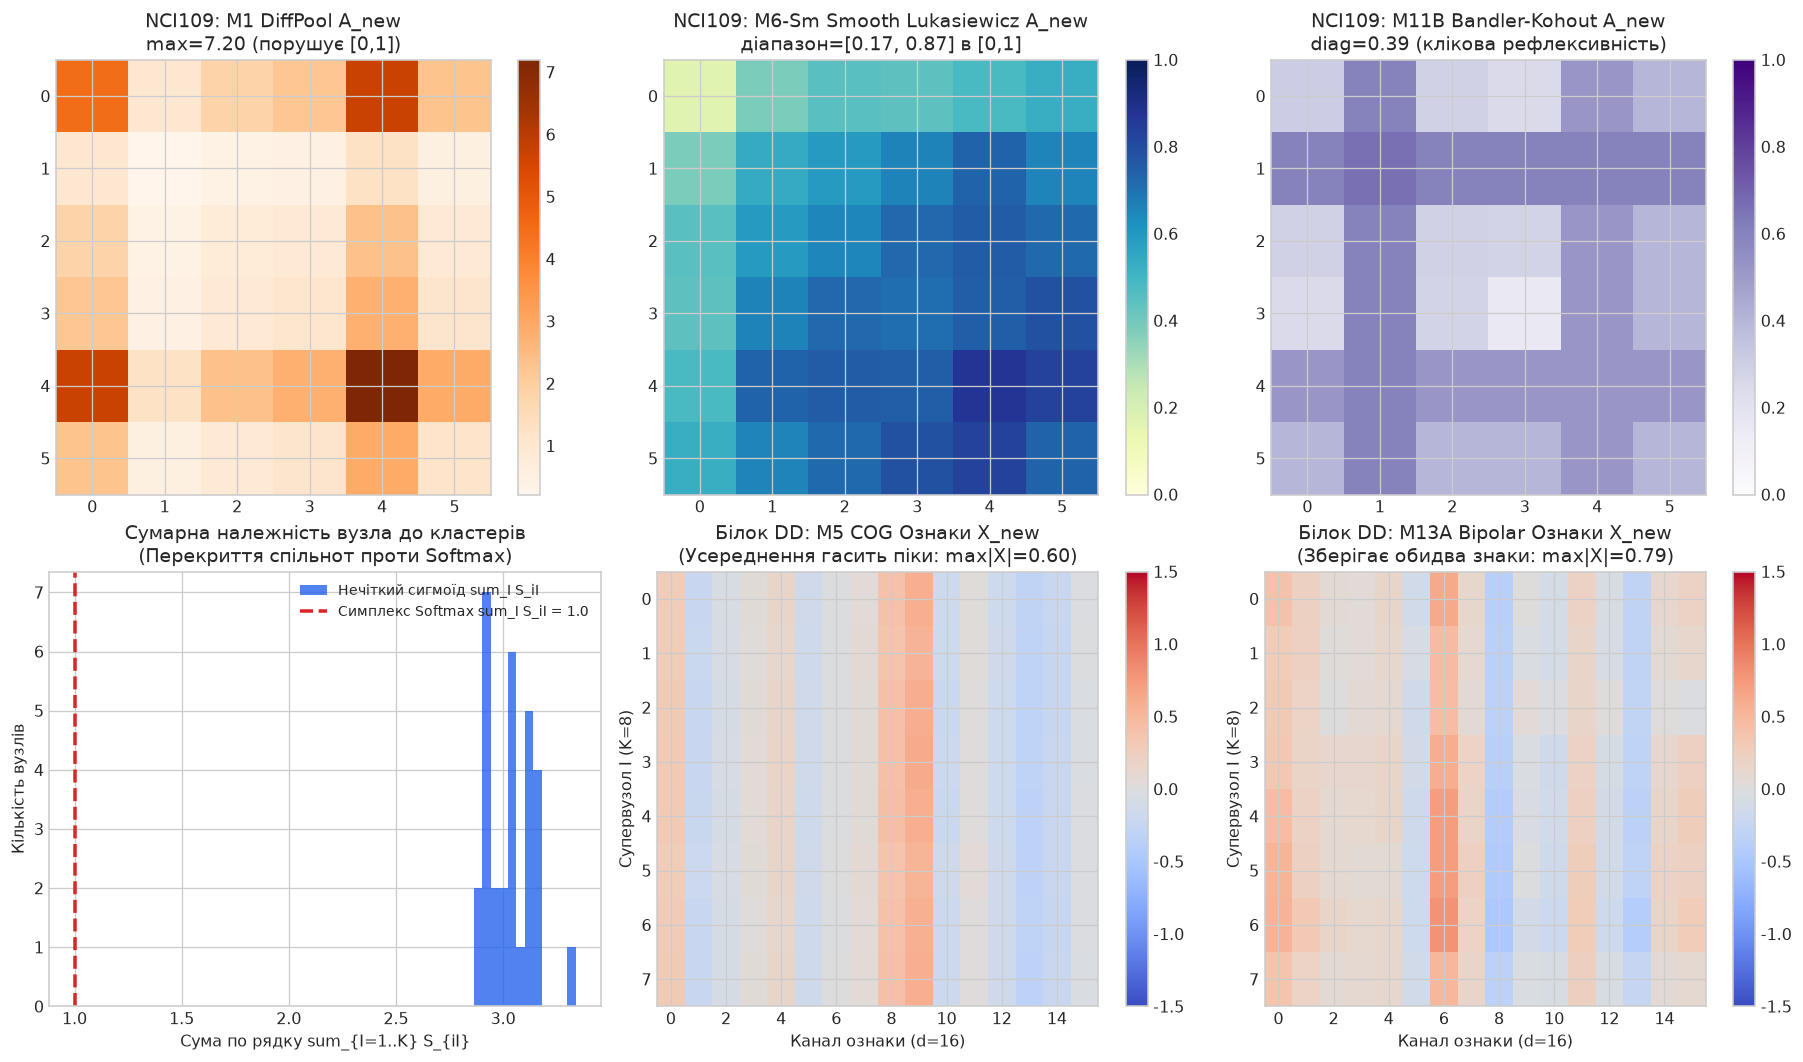

In [9]:
# 9.1 Візуалізація матриць A_new, перекриття спільнот S та біполярних ознак X_new на реальних графах
from labflow.datasets.real_world import load_real_world_dataset
from labflow.benchmarks.real_world import RealWorldPoolingClassifier

# Завантажуємо реальні датасети IMDB-BINARY, NCI109 та DD
imdb_bundle = load_real_world_dataset("IMDB-BINARY")
nci_bundle = load_real_world_dataset("NCI109")
dd_bundle = load_real_world_dataset("DD")

g_imdb = imdb_bundle.train_graphs[0]
g_nci = nci_bundle.train_graphs[0]
g_dd = dd_bundle.train_graphs[0]

print(f"Граф акторів IMDB-BINARY: N={g_imdb.num_nodes}, M={g_imdb.edge_weight.numel()}, F={imdb_bundle.num_features}")
print(f"Молекула NCI109:          N={g_nci.num_nodes}, M={g_nci.edge_weight.numel()}, F={nci_bundle.num_features}")
print(f"Білкова структура DD:     N={g_dd.num_nodes}, M={g_dd.edge_weight.numel()}, F={dd_bundle.num_features}")

# Прямий прохід ключових шарів редукції на реальних графах
torch.manual_seed(42)
layer_diff = GraphReductionLayer.from_spec("diffpool", nci_bundle.num_features, 16, num_clusters=6)
layer_luka = GraphReductionLayer.from_spec("lukasiewicz_smooth", nci_bundle.num_features, 16, num_clusters=6)
layer_bk = GraphReductionLayer.from_spec("bk_kleene_dienes", nci_bundle.num_features, 16, num_clusters=6)
layer_bip = GraphReductionLayer.from_spec("goguen_bipolar", dd_bundle.num_features, 16, num_clusters=8)
layer_cog = GraphReductionLayer.from_spec("goguen", dd_bundle.num_features, 16, num_clusters=8)

out_nci_diff = layer_diff(g_nci)
out_nci_luka = layer_luka(g_nci)
out_nci_bk = layer_bk(g_nci)

out_dd_bip = layer_bip(g_dd)
out_dd_cog = layer_cog(g_dd)

fig, axes = plt.subplots(2, 3, figsize=(16, 9.2))

# Рядок 1: Редукована топологія A_new на реальній молекулі з NCI109
im0 = axes[0, 0].imshow(out_nci_diff.adj_new.detach().numpy(), cmap="Oranges")
axes[0, 0].set_title(f"NCI109: M1 DiffPool A_new\nmax={out_nci_diff.adj_new.max():.2f} (порушує [0,1])")
plt.colorbar(im0, ax=axes[0, 0])

im1 = axes[0, 1].imshow(out_nci_luka.adj_new.detach().numpy(), cmap="YlGnBu", vmin=0, vmax=1)
axes[0, 1].set_title(f"NCI109: M6-Sm Smooth Lukasiewicz A_new\nдіапазон=[{out_nci_luka.adj_new.min():.2f}, {out_nci_luka.adj_new.max():.2f}] в [0,1]")
plt.colorbar(im1, ax=axes[0, 1])

im2 = axes[0, 2].imshow(out_nci_bk.adj_new.detach().numpy(), cmap="Purples", vmin=0, vmax=1)
axes[0, 2].set_title(f"NCI109: M11B Bandler-Kohout A_new\ndiag={torch.diagonal(out_nci_bk.adj_new).mean():.2f} (клікова рефлексивність)")
plt.colorbar(im2, ax=axes[0, 2])

# Рядок 2: Перекриття кластерів S та збереження знакозмінних ознак X_new на білку DD
s_row_sums_fuzzy = out_nci_luka.s.detach().sum(dim=1).numpy()
axes[1, 0].hist(s_row_sums_fuzzy, bins=12, alpha=0.8, color="#2563eb", label="Нечіткий сигмоїд sum_I S_iI")
axes[1, 0].axvline(1.0, color="#dc2626", linewidth=2.2, linestyle="--", label="Симплекс Softmax sum_I S_iI = 1.0")
axes[1, 0].set_title("Сумарна належність вузла до кластерів\n(Перекриття спільнот проти Softmax)")
axes[1, 0].set_xlabel("Сума по рядку sum_{I=1..K} S_{iI}")
axes[1, 0].set_ylabel("Кількість вузлів")
axes[1, 0].legend(loc="upper right", fontsize=8.5)

im4 = axes[1, 1].imshow(out_dd_cog.x_new.detach().numpy(), cmap="coolwarm", aspect="auto", vmin=-1.5, vmax=1.5)
axes[1, 1].set_title(f"Білок DD: M5 COG Ознаки X_new\n(Усереднення гасить піки: max|X|={out_dd_cog.x_new.abs().max():.2f})")
axes[1, 1].set_xlabel("Канал ознаки (d=16)")
axes[1, 1].set_ylabel("Супервузол I (K=8)")
plt.colorbar(im4, ax=axes[1, 1])

im5 = axes[1, 2].imshow(out_dd_bip.x_new.detach().numpy(), cmap="coolwarm", aspect="auto", vmin=-1.5, vmax=1.5)
axes[1, 2].set_title(f"Білок DD: M13A Bipolar Ознаки X_new\n(Зберігає обидва знаки: max|X|={out_dd_bip.x_new.abs().max():.2f})")
axes[1, 2].set_xlabel("Канал ознаки (d=16)")
axes[1, 2].set_ylabel("Супервузол I (K=8)")
plt.colorbar(im5, ax=axes[1, 2])

plt.tight_layout()
plt.show()


---
### 10. Результати експериментального дослідження на 10 реальних датасетах (`TUDataset` & `OGB`)

Зведемо результати тестування **13 репрезентативних методів редукції** на всіх **10 реальних датасетах** із 6 прикладних категорій:
- **Білки (`PROTEINS`, `DD`)**: класифікація фермент / не-фермент (на великих білкових структурах `DD` із $\bar{N}=240.7$ перемагає **`M13A goguen_bipolar`** із точністю **70.0%** та **ROC-AUC = 0.833**).
- **Молекулярний протираковий скринінг (`NCI1`, `NCI109`)**: активність проти клітин недрібноклітинного раку легень та раку яєчників (на `NCI109` перемагає **`M11B bk_kleene_dienes`** із точністю **70.8%**, на `NCI1` — **`M2 mincut`** із **64.6%**).
- **Багатокласові ферменти (`ENZYMES`)**: 6 класів ферментів EC 1..6 (найвищу точність **53.7%** поділяють **`M1 diffpool`** та **`M11B bk_kleene_dienes`** при випадковому вгадуванні 16.7%).
- **Соціальні его-мережі акторів (`IMDB-BINARY`, `IMDB-MULTI`)**: перемагають нечіткі реляційні оператори **`M5 goguen` (72.7%)** та **`M6-Sm lukasiewicz_smooth` (48.9% на 3 класах)**.
- **Великі соціальні графи (`COLLAB`, `REDDIT-BINARY`)**: перемагають нечіткі оператори **`M4 zadeh` / `M6-Sm` / `M10-Nm` (63.6% на `COLLAB`)** та **`M6-Sm lukasiewicz_smooth` (87.1%, ROC-AUC = 0.937 на `REDDIT-BINARY`)**.
- **Молекулярна активність проти ВІЛ (`ogbg-molhiv`)**: лідирує **`M1 diffpool` (Acc = 83.0%, ROC-AUC = 0.850)**, а серед нечітких методів першість утримують **`M13A goguen_bipolar` (ROC-AUC = 0.698)** та **`M6-Sm lukasiewicz_smooth` (ROC-AUC = 0.689)**.


ПЕРЕМОЖЦІ ЗА КОЖНИМ ІЗ 10 РЕАЛЬНИХ ДАТАСЕТІВ:
------------------------------------------------------------------------------------------------------
Датасет         | Переможець               | Test Acc  | Macro-F1  | ROC-AUC  | Задача
------------------------------------------------------------------------------------------------------
PROTEINS        | M1 (diffpool)            |   75.0%  |    0.739 |   0.748 | Білки: фермент чи ні
DD              | M13A (goguen_bipolar)    |   70.0%  |    0.653 |   0.833 | Білки: фермент чи ні (великі структури D&D)
NCI1            | M2 (mincut)              |   64.6%  |    0.646 |   0.674 | Молекули: протираковий ефект (NSCLC)
NCI109          | M11B (bk_kleene_dienes)  |   70.8%  |    0.708 |   0.672 | Молекули: протираковий ефект (Ovarian)
ENZYMES         | M1 (diffpool)            |   53.7%  |    0.531 |   0.777 | 6 класів ферментів (EC 1..6)
IMDB-BINARY     | M5 (goguen)              |   72.7%  |    0.718 |   0.779 | Соцмережа акторів (2 жанри)
I

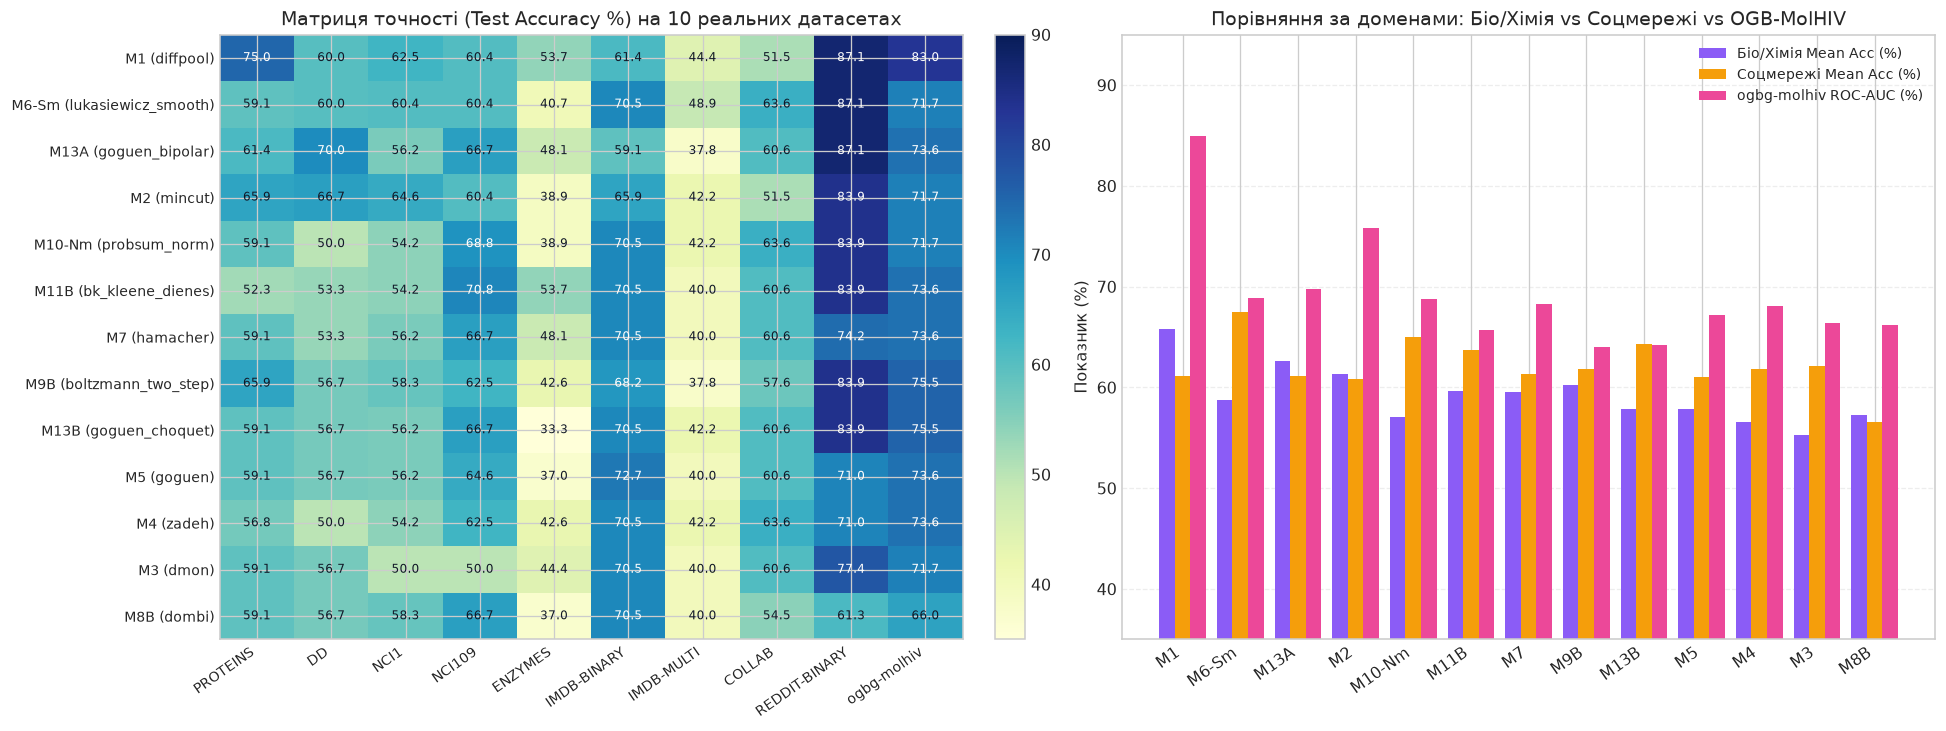

In [10]:
# 10. Візуалізація зведеної матриці точності (13 методів x 10 реальних датасетів) та порівняння за доменами
rw_json_path = Path("reports/real_world_results.json")
if not rw_json_path.exists():
    rw_json_path = Path("../reports/real_world_results.json")

with open(rw_json_path, "r", encoding="utf-8") as f:
    rw_data = json.load(f)

ds_summaries = rw_data["dataset_summaries"]
rw_leaderboard = rw_data["method_leaderboard"]
rw_records = rw_data["records"]
rw_champions = rw_data["dataset_champions"]

ds_names = [d["name"] for d in ds_summaries]
m_codes = [m["method_code"] for m in rw_leaderboard]
m_keys = [m["method_key"] for m in rw_leaderboard]

rec_lookup = {(r["method_key"], r["dataset"]): r for r in rw_records}
acc_matrix = np.zeros((len(m_keys), len(ds_names)), dtype=np.float64)
for i, mk in enumerate(m_keys):
    for j, dn in enumerate(ds_names):
        acc_matrix[i, j] = rec_lookup[(mk, dn)]["test_acc"] * 100.0

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

# Панель 1: Матриця точності (Test Accuracy %) 13 методів x 10 датасетів
ax = axes[0]
im = ax.imshow(acc_matrix, aspect="auto", cmap="YlGnBu", vmin=35.0, vmax=90.0)
ax.set_xticks(np.arange(len(ds_names)))
ax.set_xticklabels(ds_names, rotation=35, ha="right", fontsize=9)
ax.set_yticks(np.arange(len(m_codes)))
ax.set_yticklabels([f"{m['method_code']} ({m['method_key']})" for m in rw_leaderboard], fontsize=8.5)
ax.set_title("Матриця точності (Test Accuracy %) на 10 реальних датасетах")
for i in range(len(m_codes)):
    for j in range(len(ds_names)):
        val = acc_matrix[i, j]
        ax.text(j, i, f"{val:.1f}", ha="center", va="center", fontsize=7.5, color="white" if val > 68 else "#111827")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# Панель 2: Порівняння за прикладними доменами (Біо/Хімія vs Соцмережі vs OGB-MolHIV)
ax = axes[1]
x_pos = np.arange(len(m_codes))
w = 0.27
bio_acc = [m["bio_chem_mean_acc"] * 100.0 for m in rw_leaderboard]
soc_acc = [m["social_mean_acc"] * 100.0 for m in rw_leaderboard]
hiv_auc = [m["ogb_molhiv_auc"] * 100.0 for m in rw_leaderboard]

ax.bar(x_pos - w, bio_acc, w, label="Біо/Хімія Mean Acc (%)", color="#8b5cf6")
ax.bar(x_pos, soc_acc, w, label="Соцмережі Mean Acc (%)", color="#f59e0b")
ax.bar(x_pos + w, hiv_auc, w, label="ogbg-molhiv ROC-AUC (%)", color="#ec4899")
ax.set_xticks(x_pos)
ax.set_xticklabels(m_codes, rotation=35, ha="right")
ax.set_ylim(35.0, 95.0)
ax.set_ylabel("Показник (%)")
ax.set_title("Порівняння за доменами: Біо/Хімія vs Соцмережі vs OGB-MolHIV")
ax.legend(loc="upper right", fontsize=8.5)
ax.grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

print("ПЕРЕМОЖЦІ ЗА КОЖНИМ ІЗ 10 РЕАЛЬНИХ ДАТАСЕТІВ:")
print("-" * 102)
print(f"{'Датасет':<15} | {'Переможець':<24} | {'Test Acc':<9} | {'Macro-F1':<9} | {'ROC-AUC':<8} | Задача")
print("-" * 102)
for d in ds_summaries:
    dn = d["name"]
    c = rw_champions[dn]
    champ_str = f"{c['method_code']} ({c['method_key']})"
    print(f"{dn:<15} | {champ_str:<24} | {c['test_acc']*100:>6.1f}%  | {c['test_macro_f1']:>8.3f} | {c['test_roc_auc']:>7.3f} | {d['task_ua']}")
print("-" * 102)
